This is to explore Long Short-Term Memory (LSTM) networks, a type of recurrent neural network (RNN), be use for stock price prediction

In [66]:
#
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

#import os
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_squared_error

import yfinance as yf

In [67]:
import warnings
warnings.filterwarnings("ignore")

In [68]:
# Data source from yfinance, tentatively retreive 3 years stock data for training

company = "0386.HK"
df_HKstock = yf.download(company, start="2023-01-01", end="2026-10-01",
                    auto_adjust=True ).droplevel('Ticker', axis=1)
df_HKstock

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Date,,,,,
2023-01-03,2.919594,2.934880,2.858451,2.858451,58084791
2023-01-04,2.927237,2.927237,2.889022,2.919594,72997430
2023-01-05,2.911951,2.942522,2.904308,2.934880,70281193
2023-01-06,2.904308,2.927237,2.896665,2.927237,50935388
2023-01-09,2.934880,2.942522,2.911951,2.927237,56317277
...,...,...,...,...,...
2026-09-24,4.485000,4.505000,4.405000,4.415000,117509056
2026-09-25,4.425000,4.475000,4.410000,4.460000,77682942
2026-09-28,4.500000,4.530000,4.440000,4.440000,116068405


In [69]:
# Save copy to CSV
df_HKstock.to_csv('0386.HK.csv')

In [70]:
#
df_source = pd.read_csv("0386.HK.csv")
df_source

,Date,Close,High,Low,Open,Volume
0,2023-01-03,2.919594,2.934880,2.858451,2.858451,58084791
1,2023-01-04,2.927237,2.927237,2.889022,2.919594,72997430
2,2023-01-05,2.911951,2.942522,2.904308,2.934880,70281193
3,2023-01-06,2.904308,2.927237,2.896665,2.927237,50935388
4,2023-01-09,2.934880,2.942522,2.911951,2.927237,56317277
...,...,...,...,...,...,...
914,2026-09-24,4.485000,4.505000,4.405000,4.415000,117509056
915,2026-09-25,4.425000,4.475000,4.410000,4.460000,77682942
916,2026-09-28,4.500000,4.530000,4.440000,4.440000,116068405
917,2026-09-29,4.405000,4.525000,4.385000,4.525000,102217211


In [71]:
# Set Date
df_source["Date"] = pd.to_datetime(df_source["Date"], format="%Y-%m-%d")
df_source

,Date,Close,High,Low,Open,Volume
0,2023-01-03,2.919594,2.934880,2.858451,2.858451,58084791
1,2023-01-04,2.927237,2.927237,2.889022,2.919594,72997430
2,2023-01-05,2.911951,2.942522,2.904308,2.934880,70281193
3,2023-01-06,2.904308,2.927237,2.896665,2.927237,50935388
4,2023-01-09,2.934880,2.942522,2.911951,2.927237,56317277
...,...,...,...,...,...,...
914,2026-09-24,4.485000,4.505000,4.405000,4.415000,117509056
915,2026-09-25,4.425000,4.475000,4.410000,4.460000,77682942
916,2026-09-28,4.500000,4.530000,4.440000,4.440000,116068405
917,2026-09-29,4.405000,4.525000,4.385000,4.525000,102217211


In [72]:
df_source.info()

<class 'pandas.DataFrame'>
RangeIndex: 919 entries, 0 to 918
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    919 non-null    datetime64[us]
 1   Close   919 non-null    float64       
 2   High    919 non-null    float64       
 3   Low     919 non-null    float64       
 4   Open    919 non-null    float64       
 5   Volume  919 non-null    int64         
dtypes: datetime64[us](1), float64(4), int64(1)
memory usage: 43.2 KB


In [73]:
# Set Date as index - time series data
df_source = df_source.set_index('Date', ) 
df_source.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 919 entries, 2023-01-03 to 2026-09-30
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   919 non-null    float64
 1   High    919 non-null    float64
 2   Low     919 non-null    float64
 3   Open    919 non-null    float64
 4   Volume  919 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 43.1 KB


In [74]:
df = df_source
df

,Close,High,Low,Open,Volume
Date,,,,,
2023-01-03,2.919594,2.934880,2.858451,2.858451,58084791
2023-01-04,2.927237,2.927237,2.889022,2.919594,72997430
2023-01-05,2.911951,2.942522,2.904308,2.934880,70281193
2023-01-06,2.904308,2.927237,2.896665,2.927237,50935388
2023-01-09,2.934880,2.942522,2.911951,2.927237,56317277
...,...,...,...,...,...
2026-09-24,4.485000,4.505000,4.405000,4.415000,117509056
2026-09-25,4.425000,4.475000,4.410000,4.460000,77682942
2026-09-28,4.500000,4.530000,4.440000,4.440000,116068405


In [75]:
# Data pre-processing
df.isnull().sum()

Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

In [76]:
# This is preserve as for handling missing values, if applicable
df.bfill()

,Close,High,Low,Open,Volume
Date,,,,,
2023-01-03,2.919594,2.934880,2.858451,2.858451,58084791
2023-01-04,2.927237,2.927237,2.889022,2.919594,72997430
2023-01-05,2.911951,2.942522,2.904308,2.934880,70281193
2023-01-06,2.904308,2.927237,2.896665,2.927237,50935388
2023-01-09,2.934880,2.942522,2.911951,2.927237,56317277
...,...,...,...,...,...
2026-09-24,4.485000,4.505000,4.405000,4.415000,117509056
2026-09-25,4.425000,4.475000,4.410000,4.460000,77682942
2026-09-28,4.500000,4.530000,4.440000,4.440000,116068405


In [77]:
# Calculate moving averages and daily returns

df['20-day MA'] = df['Close'].rolling(window=20).mean()
df['50-day MA'] = df['Close'].rolling(window=50).mean()
df['Daily Return'] = df['Close'].pct_change()

In [78]:
# To check NaN
df[df.isna().values==True].drop_duplicates()

,Close,High,Low,Open,Volume,20-day MA,50-day MA,Daily Return
Date,,,,,,,,
2023-01-03,2.919594,2.934880,2.858451,2.858451,58084791,NaN,NaN,NaN
2023-01-04,2.927237,2.927237,2.889022,2.919594,72997430,NaN,NaN,0.002618
2023-01-05,2.911951,2.942522,2.904308,2.934880,70281193,NaN,NaN,-0.005222
2023-01-06,2.904308,2.927237,2.896665,2.927237,50935388,NaN,NaN,-0.002625
2023-01-09,2.934880,2.942522,2.911951,2.927237,56317277,NaN,NaN,0.010526
2023-01-10,2.934880,2.950165,2.919594,2.934880,66480816,NaN,NaN,0.000000
2023-01-11,2.965452,2.996023,2.934880,2.934880,136384472,NaN,NaN,0.010417
2023-01-12,3.018952,3.026595,2.957808,2.957808,123655194,NaN,NaN,0.018041
2023-01-13,3.049524,3.049524,3.003666,3.041881,82369860,NaN,NaN,0.010127


In [79]:
df = df.dropna()   # Drop all NaN
df

,Close,High,Low,Open,Volume,20-day MA,50-day MA,Daily Return
Date,,,,,,,,
2023-03-16,3.531027,3.599813,3.508099,3.546313,174803627,3.343394,3.209413,-0.023256
2023-03-17,3.745029,3.760315,3.553956,3.561599,368017156,3.371673,3.225922,0.060606
2023-03-20,3.576885,3.798529,3.561599,3.699172,286854795,3.390398,3.238915,-0.044898
2023-03-21,3.584527,3.638028,3.515741,3.592170,129379902,3.407976,3.252367,0.002137
2023-03-22,3.645671,3.691529,3.607456,3.607456,136763006,3.429759,3.267194,0.017058
...,...,...,...,...,...,...,...,...
2026-09-24,4.485000,4.505000,4.405000,4.415000,117509056,4.579036,4.382318,0.008999
2026-09-25,4.425000,4.475000,4.410000,4.460000,77682942,4.568496,4.387928,-0.013378
2026-09-28,4.500000,4.530000,4.440000,4.440000,116068405,4.560734,4.394455,0.016949


In [80]:
# Configuration

# For ~ 80:20 Split
test_days = 174

# choose the number of days on which to base our predictions 
nb_days = 30

# Number of days into the future we want to predict
n_steps_out = 10

#
#epochsMS=15 
#batch_sizeMS = 32

epochsMS=50 
batch_sizeMS = 32
epochs2=15 
batch_size2 = 32

In [81]:
# For normailized Data

# from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0,1))  
scaled_data = scaler.fit_transform(df['Close'].values.reshape(-1,1))

In [82]:
# ADF Test : p-value < 0.05 for stationary data

#from statsmodels.tsa.stattools import adfuller

close_series = df['Close']
def check_stationarity(series):
    result = adfuller(series.dropna())  # Drop NaN values if any
    print("ADF Statistic:", result[0])
    print("p-value:", result[1])
    if result[1] < 0.05:
        print("The series is stationary.")
    else:
        print("The series is not stationary.")

check_stationarity(close_series)

ADF Statistic: -2.338992130435247
p-value: 0.15970034865594385
The series is not stationary.


# To transform time series stationary...
There are three major time series patterns: trend, seasonality, and cycles. Trend and cycles are usually combined into a single component, with a trend-cycle component, a seasonal component, and a remainder component (containing the rest of the time series).

To make time series stationary, the principle is to estimate trend and seasonality, and to remove those from the time series. Then to apply the forecasting technique (i.e here LSTM), the final step being to convert the forcasted values into the original scale by adding the estimated trend and seasonality.

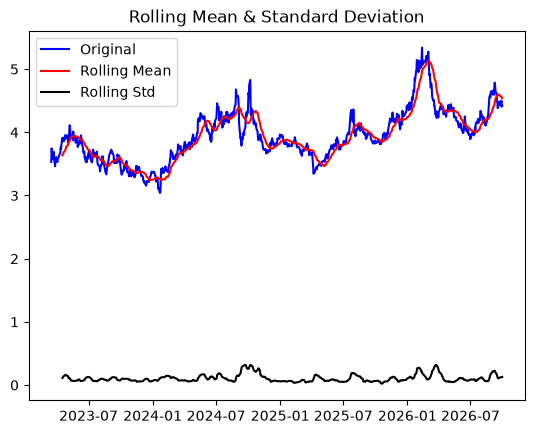

Results of Dickey-Fuller Test:
Test Statistic                  -2.338992
p-value                          0.159700
#Lags Used                       0.000000
Number of Observations Used    869.000000
Critical Value (1%)             -3.437897
Critical Value (5%)             -2.864872
Critical Value (10%)            -2.568544
dtype: float64


In [18]:
#... The following cells are use for model(s), such as LSTM in transformation
#... test stationarity with DFT

close_series = df['Close']
def test_stationarity(timeseries):
    '''
    Input: timeseries (dataframe): timeseries for which we want to study the stationarity
    '''
    
    #Determing rolling statistics
    rolmean = timeseries.rolling(20).mean()
    rolstd = timeseries.rolling(20).std()

    #Plot rolling statistics:
    orig = plt.plot(timeseries, color='blue',label='Original')
    mean = plt.plot(rolmean, color='red', label='Rolling Mean')
    std = plt.plot(rolstd, color='black', label = 'Rolling Std')
    plt.legend(loc='best')
    plt.title('Rolling Mean & Standard Deviation')
    plt.show(block=False)

    #Perform Dickey-Fuller test:
    print('Results of Dickey-Fuller Test:')
    dftest = adfuller(timeseries, autolag='AIC')
    dfoutput = pd.Series(dftest[0:4], index=['Test Statistic','p-value',\
                                             '#Lags Used','Number of Observations Used'])
    for key,value in dftest[4].items():
        dfoutput['Critical Value (%s)'%key] = value
    print(dfoutput)

test_stationarity(close_series)

<Figure size 640x480 with 0 Axes>

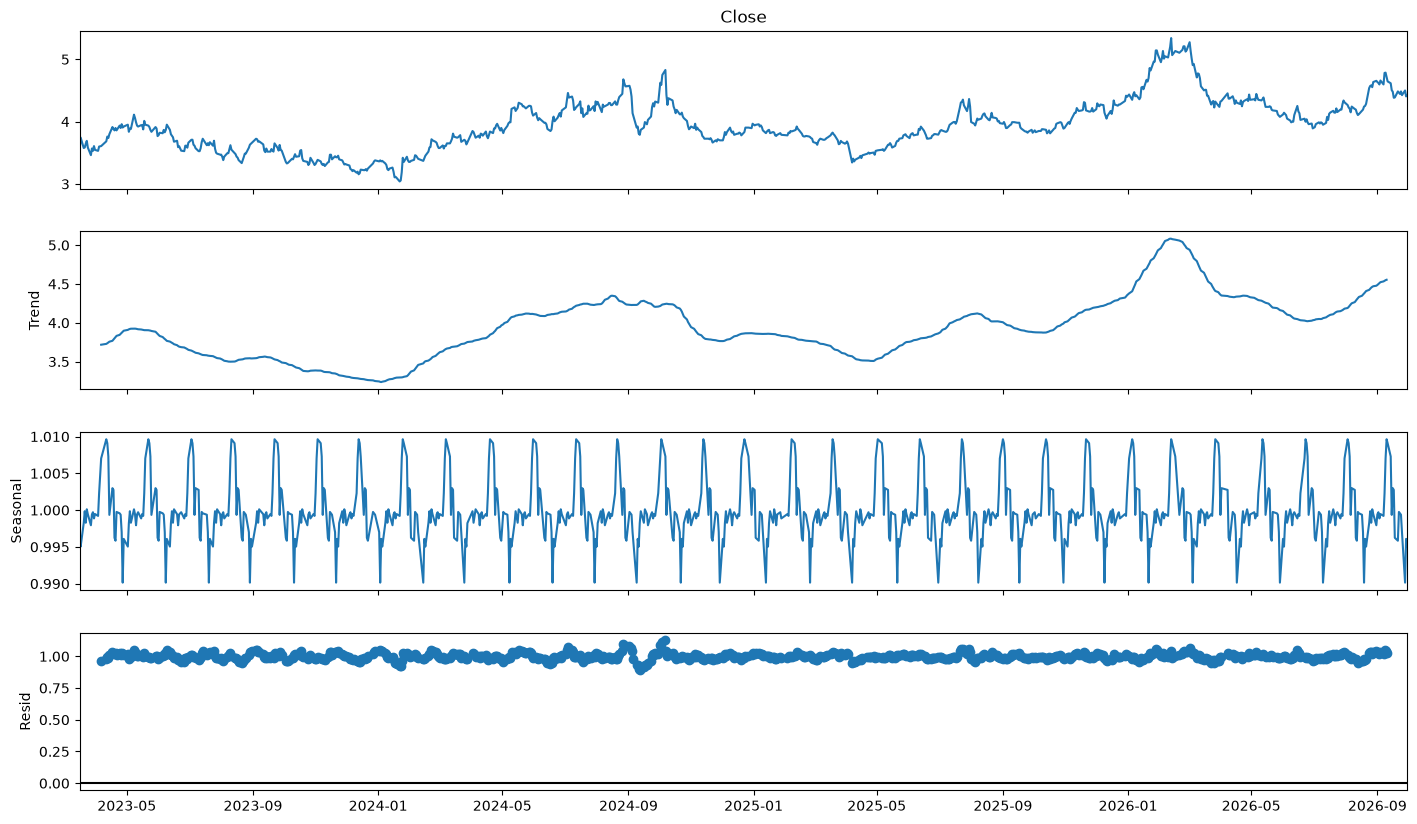

In [19]:
#from statsmodels.tsa.seasonal import seasonal_decompose

#To plot & view the trend and the seasonality
# here set the period to 28 as monthly average 

df_close = df['Close']
result = seasonal_decompose(df_close, model='multiplicative',period=28)
fig = plt.figure()  
fig = result.plot()  
fig.set_size_inches(16, 9)

Text(0.5, 1.0, 'Transformed data')

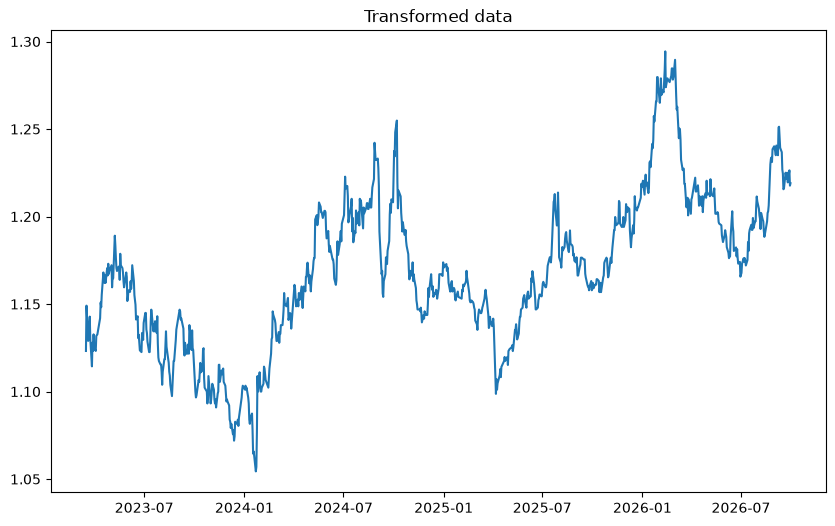

In [20]:
#... To apply log transform to reduce the trends effect while square root transform to flatten 

df_close_log = df_close.apply(np.log)
df_close_tf = df_close_log.apply(np.sqrt)

plt.figure(figsize = (10,6))
plt.plot(df_close_tf)
plt.title('Transformed data')

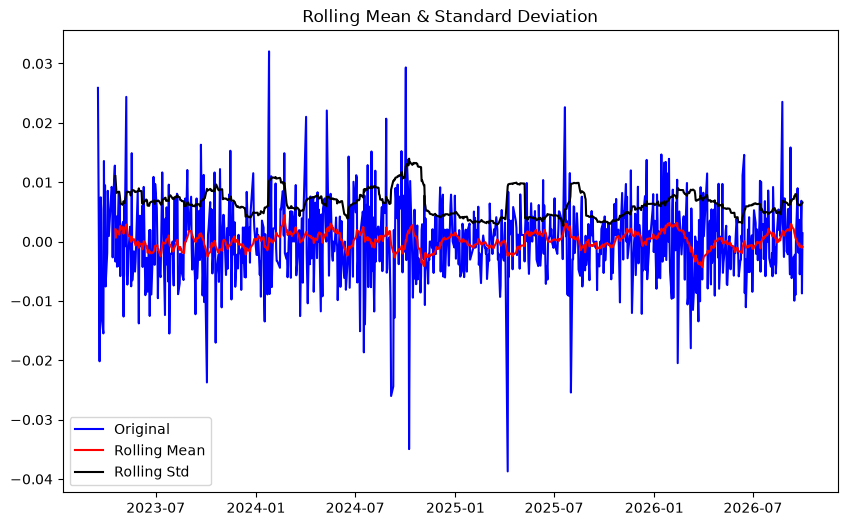

Results of Dickey-Fuller Test:
Test Statistic                 -30.069255
p-value                          0.000000
#Lags Used                       0.000000
Number of Observations Used    868.000000
Critical Value (1%)             -3.437906
Critical Value (5%)             -2.864876
Critical Value (10%)            -2.568546
dtype: float64


In [21]:
#... classical methold differenciating to handel with trand and seasonality
df_close_shift = df_close_tf - df_close_tf.shift()

df_close_shift.dropna(inplace=True)
plt.figure(figsize = (10,6))
test_stationarity(df_close_shift)

check p-value

In [22]:
#...MS LSTM
def preprocess_lstm(sequence, n_steps,n_features):
    X, y = list(), list()
    for i in range(len(sequence)):
        # find the end of this pattern
        end_ix = i + n_steps
        # check if we are beyond the sequence
        if end_ix >= len(sequence):
            break
        # gather input and output parts of the pattern
        seq_x, seq_y = sequence[i:end_ix], sequence[end_ix]
        X.append(seq_x)
        y.append(seq_y)
        
    X = np.array(X)
    y = np.array(y)

    X = X.reshape((X.shape[0], X.shape[1], n_features))
    return X, y

# choose the number of days on which to base our predictions 
#nb_days = 60
n_features = 1

X, y = preprocess_lstm(df_close_shift.to_numpy(), nb_days, n_features)

#Split the data set between the training set and the test set (20%)
#test_days = 135 

X_train, y_train = X[:-test_days], y[:-test_days]
X_test, y_test = X[-test_days:], y[-test_days:]

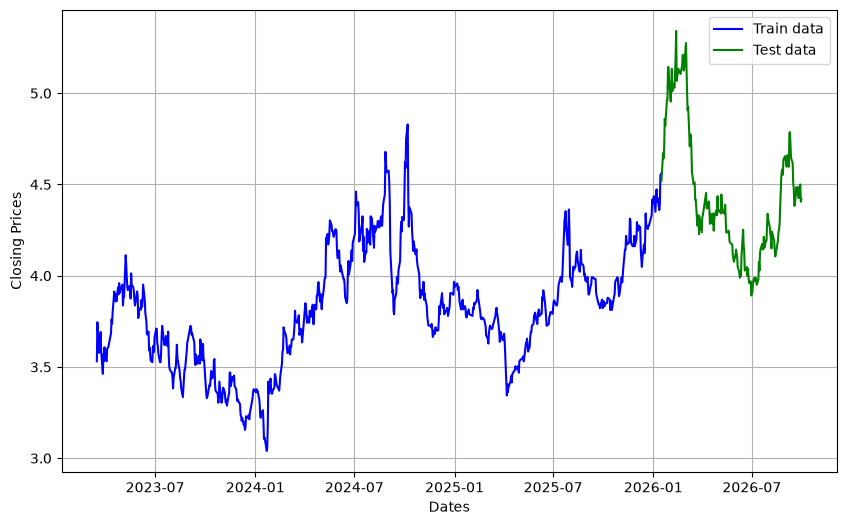

In [23]:
#... Split Data
train_original = df_close.iloc[:-test_days]
test_original = df_close.iloc[-test_days:]

plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Closing Prices')
plt.plot(train_original, 'b', label='Train data')
plt.plot(test_original, 'g', label='Test data')
plt.legend()

In [24]:
#... LSTM Vanilla LSTM
def vanilla_LSTM():
    model = Sequential()    
    model.add(LSTM(units=50, input_shape=(nb_days, n_features)))
    model.add(Dense(1))
    return model

#
model = vanilla_LSTM()
model.summary()
model.compile(optimizer='adam', 
              loss='mean_squared_error',
              metrics=[tf.keras.metrics.MeanAbsoluteError()])    

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 50)                  │          10,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
#...Train and evaluate model
model.fit(X_train, 
          y_train, 
          epochs=epochsMS, 
          batch_size = batch_sizeMS)

Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 6.2651e-05 - mean_absolute_error: 0.0060
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 4.8638e-05 - mean_absolute_error: 0.0051
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 4.7473e-05 - mean_absolute_error: 0.0050
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 4.7975e-05 - mean_absolute_error: 0.0050
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 4.7528e-05 - mean_absolute_error: 0.0050
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 4.7423e-05 - mean_absolute_error: 0.0050
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 5.1818e-05 - mean_absolute_error: 0.0052
Epoch 8/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 4.7430e-05 - mean_absolute_error: 0.0050
Epoch 9/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 4.7561e-05 - mean_absolute_error: 0.0050
Epoch 10/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 5.0830e-05 - mean_absolute_error: 0.0053

In [26]:
#...
# Evaluate the model on the test data using
print("Evaluate on test data")
results = model.evaluate(X_test, y_test, batch_size=32)
print("Test MSE:", results[0])
print("Test MAE:", results[1])

Evaluate on test data
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 4.3217e-05 - mean_absolute_error: 0.0050  
Test MSE: 4.3217431084485725e-05
Test MAE: 0.005044872872531414


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


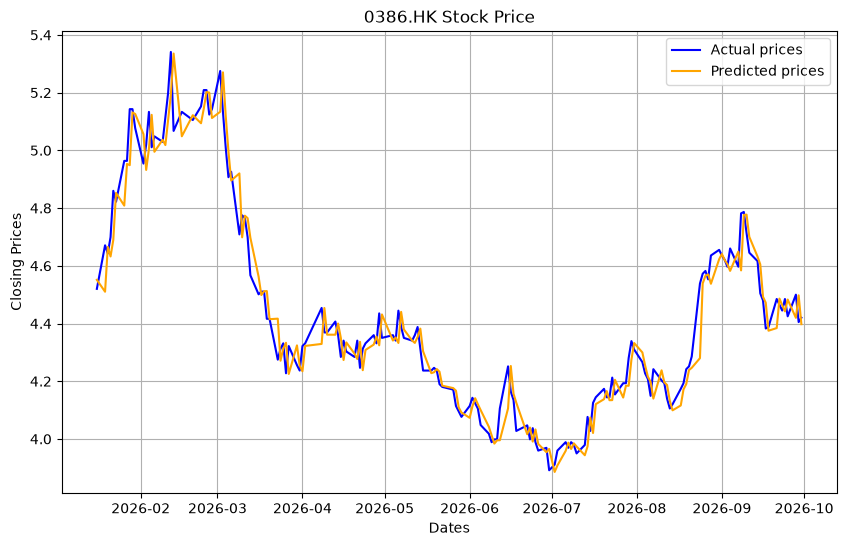

In [27]:
#...
# Prediction
y_pred = model.predict(X_test)

# We create a dataframe from y_pred to have date-time indexes.
pred_data = pd.DataFrame(y_pred[:,0], test_original.index,columns=['Close'])

# Apply inverse transformation from 1.d

# Add the differenciation term
pred_data['Close'] = pred_data['Close'] + df_close_tf.shift().values[-test_days:] 

# Take the square, and the exponent
pred_data = pred_data.apply(np.square)
pred_data = pred_data.apply(np.exp)

# Plot actual prices vs predicted prices 
plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Closing Prices')
plt.plot(test_original,'b',label='Actual prices')
plt.plot(pred_data, 'orange',label='Predicted prices')
#plt.title(' Stock Price')
plt.title(company + ' Stock Price')

plt.legend()

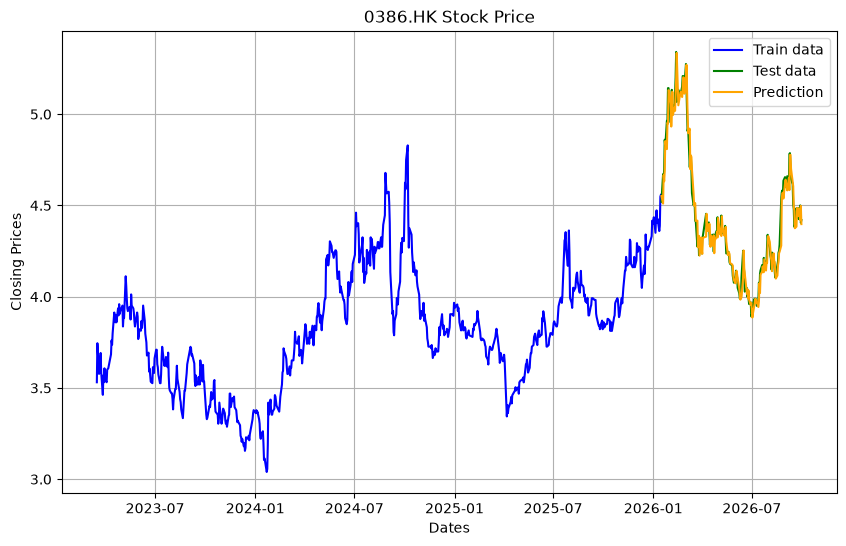

In [28]:
#...
plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Closing Prices')
plt.plot(train_original, 'b', label='Train data')
plt.plot(test_original, 'g', label='Test data')
plt.plot(pred_data, 'orange', label='Prediction')
plt.title(company + ' Stock Price')
plt.legend()

In [29]:
#...Multiple-Step LSTM
def preprocess_multistep_lstm(sequence, n_steps_in, n_steps_out, features):
    X, y = list(), list()
    for i in range(len(sequence)):
        # find the end of this pattern
        end_ix = i + n_steps_in
        out_end_ix = end_ix + n_steps_out
        # check if we are beyond the sequence
        if out_end_ix > len(sequence):
            break
        # gather input and output parts of the pattern
        seq_x, seq_y = sequence[i:end_ix], sequence[end_ix:out_end_ix]
        X.append(seq_x)
        y.append(seq_y)

    X = np.array(X)
    y = np.array(y)

    X = X.reshape((X.shape[0], X.shape[1], n_features))
    
    return X, y

# Number of days into the future we want to predict
#n_steps_out = 30

# choose the number of days on which to base our predictions 
#nb_days = 60

n_features = 1

X, y = preprocess_multistep_lstm(df_close_shift.to_numpy(), nb_days, n_steps_out, n_features)

#
#Split the data set between the training set and the test set (20%)
#test_days = 135 

X_train, y_train = X[:-test_days], y[:-test_days]
X_test, y_test = X[-test_days:], y[-test_days:]

In [30]:
#...
def vanilla_multistep_LSTM():
    model = Sequential()    
    model.add(LSTM(units=50, input_shape=(nb_days, n_features)))
    model.add(Dense(n_steps_out))
    return model

#
model = vanilla_multistep_LSTM()
model.summary()
model.compile(optimizer='adam', 
              loss='mean_squared_error',
              metrics=[tf.keras.metrics.MeanAbsoluteError()])

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                        │ (None, 50)                  │          10,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             510 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 10,910 (42.62 KB)

 Trainable params: 10,910 (42.62 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
#...
model.fit(X_train, 
          y_train, 
          epochs=epochsMS, 
          batch_size = batch_sizeMS)

Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 4.9444e-05 - mean_absolute_error: 0.0051
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 4.8538e-05 - mean_absolute_error: 0.0051
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 4.7335e-05 - mean_absolute_error: 0.0050
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 4.8272e-05 - mean_absolute_error: 0.0051
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 4.7455e-05 - mean_absolute_error: 0.0050
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 4.7540e-05 - mean_absolute_error: 0.0050
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 4.7603e-05 - mean_absolute_error: 0.0050
Epoch 8/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 4.8799e-05 - mean_absolute_error: 0.0051
Epoch 9/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 4.8829e-05 - mean_absolute_error: 0.0051
Epoch 10/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 4.7533e-05 - mean_absolute_error: 0.0050

In [32]:
#...
# Evaluate the model on the test set
print("Evaluate on test data")
results = model.evaluate(X_test, y_test, batch_size=32)

print("Test MSE:", results[0])
print("Test MAE:", results[1])

Evaluate on test data
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 4.4506e-05 - mean_absolute_error: 0.0051 
Test MSE: 4.450564301805571e-05
Test MAE: 0.005116225685924292


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


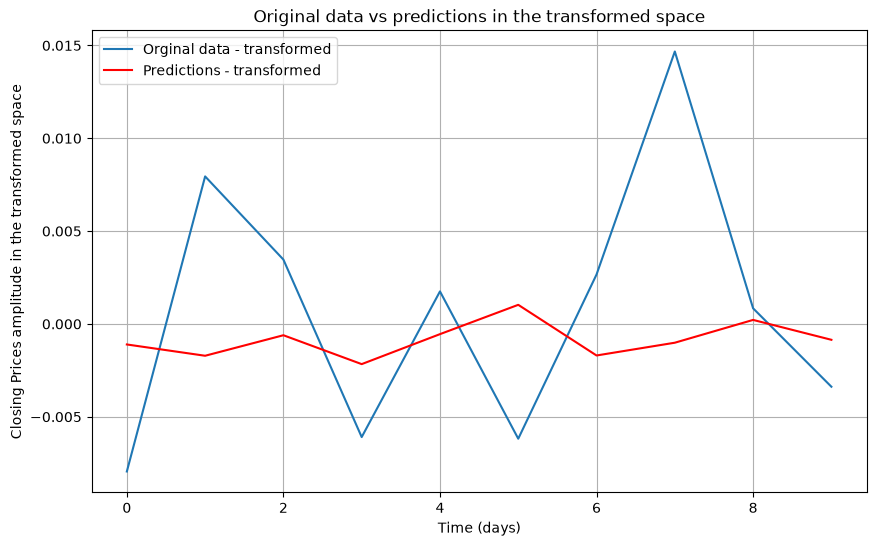

In [33]:
#...
# Prediction
y_pred = model.predict(X_test)

# the_day is the day from which we will study the n_steps_out-th dayS of prediction into 
# the future. Note: The first day start at index 0
the_day = 0
y_pred_days = y_pred[the_day,:]

plt.figure(figsize=(10,6))
plt.grid(True)
plt.plot(y_test[the_day,:],label='Orginal data - transformed')
plt.plot(y_pred_days, color='red',label='Predictions - transformed')
plt.xlabel('Time (days)')
plt.ylabel('Closing Prices amplitude in the transformed space')
plt.title('Original data vs predictions in the transformed space')
plt.legend()

In [34]:
#...
# Apply inverse transformations from 3.a

# Add the differenciation term
pred_diff_cumsum = y_pred_days.cumsum()

base_number = df_close_tf.values[-test_days+the_day+nb_days-1]
idx = test_original.iloc[the_day:the_day+n_steps_out].index

pred_tf = pd.Series(base_number, index=idx)
pred_tf = pred_tf.add(pred_diff_cumsum,fill_value=0)

print(pred_tf)

Date
2026-01-16    1.277871
2026-01-19    1.276158
2026-01-20    1.275550
2026-01-21    1.273387
2026-01-22    1.272838
2026-01-23    1.273869
2026-01-26    1.272171
2026-01-27    1.271161
2026-01-28    1.271378
2026-01-29    1.270525
dtype: float64


In [35]:
#...
# Take the square, and the exponent
pred_log = pred_tf.apply(np.square)
pred = pred_log.apply(np.exp)
print(pred)

Date
2026-01-16    5.118978
2026-01-19    5.096631
2026-01-20    5.088733
2026-01-21    5.060749
2026-01-22    5.053685
2026-01-23    5.066963
2026-01-26    5.045108
2026-01-27    5.032160
2026-01-28    5.034944
2026-01-29    5.024035
dtype: float64


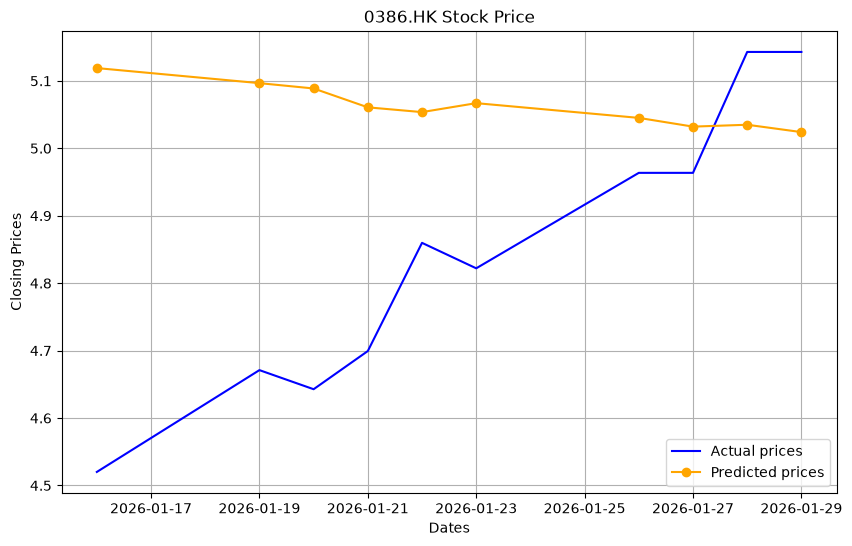

In [36]:
#...
# Plot actual prices vs predicted prices 
plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Closing Prices')
plt.plot(test_original.iloc[max(0,the_day-30):the_day+n_steps_out],'b',label='Actual prices')
plt.plot(pred, '-o',color='orange',label='Predicted prices')
plt.title(company + ' Stock Price')

plt.legend()

In [37]:
#import pandas as pd
#import numpy as np
#import matplotlib.pyplot as plt
#import seaborn as sns
from sklearn.metrics import r2_score
import statsmodels.api as sm

# 1. Extract the exact actual prices that align with the prediction period
# Based on your plot, 'pred' starts at 'the_day' and goes forward for 'n_steps_out' steps.
actual_for_pred_period = test_original.iloc[the_day : the_day + n_steps_out]

# 2. Ensure both are flattened 1D arrays/Series with no missing values
y_true = actual_for_pred_period.values.flatten()
y_pred = pred.flatten() if hasattr(pred, 'flatten') else pred

X = sm.add_constant(y_true)

#fit linear regression model
model = sm.OLS(y_pred, X).fit()

#view model summary
summary = model.summary()
print(summary)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.867
Model:                            OLS   Adj. R-squared:                  0.850
Method:                 Least Squares   F-statistic:                     52.00
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           9.14e-05
Time:                        17:21:43   Log-Likelihood:                 31.176
No. Observations:                  10   AIC:                            -58.35
Df Residuals:                       8   BIC:                            -57.75
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.7200      0.091     62.657      0.0

In [38]:
#import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Calculate Metrics
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)  # Alternative: mean_squared_error(y_true, y_pred, squared=False)
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Calculate Directional Accuracy (Crucial for price trends)
# Compares if the predicted direction (up/down) matches the actual direction
actual_direction = np.diff(y_true) > 0
predicted_direction = np.diff(y_pred) > 0
directional_accuracy = np.mean(actual_direction == predicted_direction) * 100

# Print Evaluation Results
print("--- Model Evaluation Metrics ---")
print(f"Mean Absolute Error (MAE):      {mae:.4f}")
print(f"Mean Squared Error (MSE):       {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Pct Error (MAPE): {mape:.2f}%")
print(f"Directional Accuracy (DA):      {directional_accuracy:.2f}%")

r2 = r2_score(y_true, y_pred)
print(f"Coefficient of Determination (R²)    : {r2:.4f}")


--- Model Evaluation Metrics ---
Mean Absolute Error (MAE):      0.2647
Mean Squared Error (MSE):       0.1004
Root Mean Squared Error (RMSE): 0.3169
Mean Absolute Pct Error (MAPE): 5.62%
Directional Accuracy (DA):      44.44%
Coefficient of Determination (R²)    : -1.4835


In [83]:
# Follow from ADF Test if series is stationary
scaler = MinMaxScaler()
df['Close'] = scaler.fit_transform(df[['Close']])

In [84]:
# Train and Verify Split (80:20 Ratio)
#from sklearn.model_selection import train_test_split

def create_dataset(dataset, look_back=1):
    dataX, dataY = [], []
    for i in range(len(dataset) - look_back):
        dataX.append(dataset[i:(i + look_back)])
        dataY.append(dataset[i + look_back])
    return np.array(dataX), np.array(dataY)

close_values = df['Close'].values 

X, Y = create_dataset(close_values, look_back=30)

trainX, testX, trainY, testY = train_test_split(X, Y, test_size=0.2, shuffle=False)


In [85]:
# Data for LSTM 
trainX = np.reshape(trainX, (trainX.shape[0], trainX.shape[1], 1))
testX = np.reshape(testX, (testX.shape[0], testX.shape[1], 1))

#
LSTM(32 units) → Captures long-term dependencies

Dropout(0.2) → Prevents overfitting

Dense Layers → Produces final prediction

In [86]:
#2 LSTM
#from tensorflow.keras.models import Sequential  
#from tensorflow.keras.layers import LSTM, Dense, Dropout  

model = Sequential([  
    LSTM(units=32, return_sequences=True, input_shape=(trainX.shape[1], 1)),  
    Dropout(0.2),  
    LSTM(units=32, return_sequences=False),  
    Dropout(0.2),  
    Dense(units=16),  
    Dense(units=1)  
])  

model.compile(optimizer='adam', loss='mean_squared_error')

model.fit(trainX, trainY, epochs=epochs2, batch_size=batch_size2)

Epoch 1/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0294
Epoch 2/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0081
Epoch 3/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0064
Epoch 4/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0054
Epoch 5/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0055
Epoch 6/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0050
Epoch 7/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0047
Epoch 8/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0045
Epoch 9/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0041
Epoch 10/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0048
Epoch 11/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0044
Epoch 12/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0042
Epoch 13/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0041
Epoch 14/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0040
Epoch 15/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0037


In [87]:
# Prediction & Result
testPredict = model.predict(testX)
testPredict = scaler.inverse_transform(testPredict)
testY = scaler.inverse_transform(testY.reshape(-1, 1))

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step


In [88]:
#from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(testY, testPredict))
print(f"Root Mean Squared Error (RMSE): {rmse}")

Root Mean Squared Error (RMSE): 0.13618609971124016


In [89]:
# Evaluation Metrics (including R-squared)
mae = mean_absolute_error(testY, testPredict)
rmse = np.sqrt(mean_squared_error(testY, testPredict))
mape = np.mean(np.abs((testY - testPredict) / testY)) * 100
r2 = r2_score(testY, testPredict)

# Print Evaluation Results
print("--- Model Evaluation Metrics ---")
print(f"Mean Absolute Error (MAE):      {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Pct Error (MAPE): {mape:.2f}%")
print(f"R² Score (Goodness of Fit):     {r2:.4f}")


--- Model Evaluation Metrics ---
Mean Absolute Error (MAE):      0.1029
Root Mean Squared Error (RMSE): 0.1362
Mean Absolute Pct Error (MAPE): 2.30%
R² Score (Goodness of Fit):     0.8525


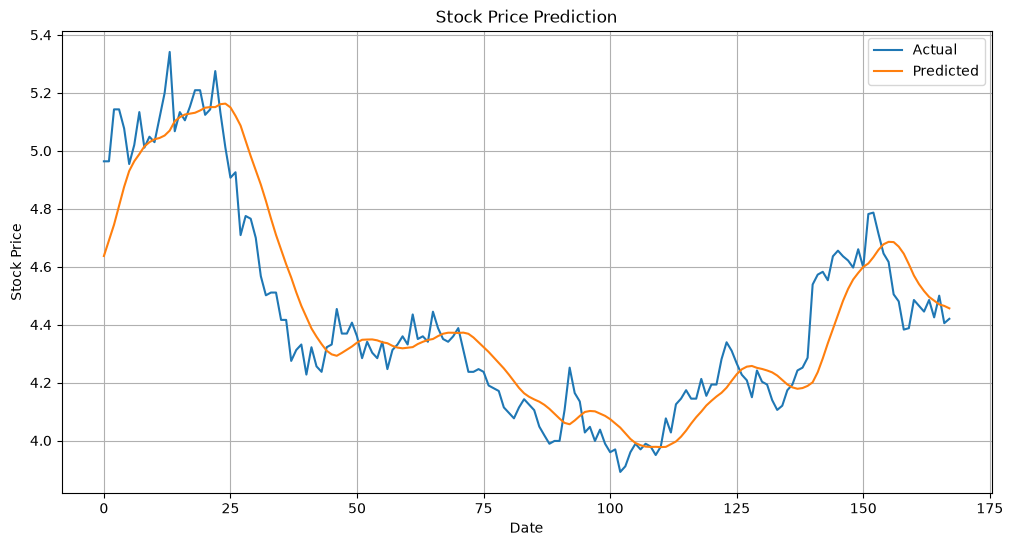

In [90]:
#2
plt.figure(figsize=(12, 6))
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.title("Stock Price Prediction")
plt.plot(testY, label='Actual')
plt.plot(testPredict, label='Predicted')
plt.grid(True)
plt.legend()
plt.show()

For this study, we will focus on the closing price, as it represents the final market sentiment for each trading day.